# Week 3 – Descriptive analytics: mean vs median
**Question:** did the price of each staple "really" go up, and which statistic should a newsroom report?

Data: my **Week 2 cleaned file**, rebuilt below from `teaching_prices_messy.csv` with the decisions in my Week 2 cleaning log, and saved as `teaching_prices_clean_week2.csv`. Put the messy CSV in the same folder as this notebook (or in `data/`).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def find(name):
    for p in [name, os.path.join("data", name)]:
        if os.path.exists(p):
            return p
    return None

pd.set_option("display.float_format", "{:.2f}".format)

## Week 2 cleaned file (rebuilt from my cleaning log)
Same decisions as my Week 2 log. I keep the **source price** in `price_source` so Part 2 can compare *with* and *without* the flagged value.

In [2]:
raw = pd.read_csv(find("teaching_prices_messy.csv"))
w2 = raw.copy()
w2["flag"] = ""

# 1. exact duplicate row -> exclude second copy
w2 = w2[~w2.duplicated()]

# 2. 'oil b' on 2026-02-05 City 1 -> Staple A
m = (w2["item"] == "oil b") & (w2["date"] == "2026-02-05") & (w2["city"] == "City 1")
w2.loc[m, "item"] = "Staple A"
w2.loc[m, "flag"] = "item relabelled from 'oil b'"

# keep source price as a number for Part 2
w2["price_source"] = pd.to_numeric(w2["price"].astype(str).str.replace(",", ""), errors="coerce")

# 3. '1,250' -> missing, flagged
m = w2["price"].astype(str) == "1,250"
w2.loc[m, "flag"] = "source price '1,250' implausible; set missing"
w2.loc[m, "price"] = None
w2["price"] = pd.to_numeric(w2["price"])

# 4. 9999 -> missing, flagged
m = w2["price"] == 9999
w2.loc[m, "flag"] = "source price 9999 (missing-value code); set missing"
w2.loc[m, "price"] = float("nan")

# 5. blank price -> retain, flag
w2.loc[w2["price"].isna() & (w2["flag"] == ""), "flag"] = "price missing in source"

w2["date"] = pd.to_datetime(w2["date"])
w2 = w2.sort_values(["date", "item", "city"]).reset_index(drop=True)

print(w2.shape)
w2[w2["flag"] != ""][["date", "item", "city", "price_source", "price", "flag"]]

(96, 8)


,date,item,city,price_source,price,flag
3,2026-01-01,Pulse C,City 2,NaN,NaN,price missing in source
21,2026-01-15,Staple A,City 2,1250.00,NaN,"source price '1,250' implausible; set missing"
30,2026-01-22,Sweetener D,City 1,9999.00,NaN,source price 9999 (missing-value code); set mi...
44,2026-02-05,Staple A,City 1,108.50,108.50,item relabelled from 'oil b'


In [3]:
w2.drop(columns="price_source").to_csv("teaching_prices_clean_week2.csv", index=False)
df = w2[["date", "item", "city", "price", "unit", "data_label", "flag"]].copy()
print(df.shape)
print(df["item"].value_counts())
print("missing prices:", df["price"].isna().sum())

(96, 7)
item
Oil B          24
Pulse C        24
Staple A       24
Sweetener D    24
Name: count, dtype: int64
missing prices: 3


## Part 1 – Mean, median and first-to-last % change per item
- **Mean / median:** over all weeks and both cities (missing prices excluded).
- **First-to-last % change:** average of the two cities on the first date vs the last date. If a city is missing on that date, the change is computed on the city that has both ends (see the per-city table).

In [4]:
first_date, last_date = df["date"].min(), df["date"].max()
print("first date:", first_date.date(), " last date:", last_date.date(), " weeks:", df['date'].nunique())

g = df.groupby("item")["price"]
stats = pd.DataFrame({
    "n": g.count(),
    "mean": g.mean(),
    "median": g.median(),
    "min": g.min(),
    "max": g.max(),
    "sd": g.std(),
})
stats["mean_minus_median"] = stats["mean"] - stats["median"]

# first-to-last, per city
fl = (df[df["date"].isin([first_date, last_date])]
      .pivot_table(index=["item", "city"], columns="date", values="price"))
fl.columns = ["first", "last"]
fl["pct_change"] = (fl["last"] / fl["first"] - 1) * 100
display(fl)

# first-to-last, item level (average of cities with both ends)
both = fl.dropna(subset=["first", "last"])
item_fl = both.groupby("item")[["first", "last"]].mean()
item_fl["pct_change"] = (item_fl["last"] / item_fl["first"] - 1) * 100
stats = stats.join(item_fl)
stats.round(2)

first date: 2026-01-01  last date: 2026-03-19  weeks: 12


first   last  pct_change
item        city                            
Oil B       City 1 298.00 344.00       15.44
            City 2 304.00 350.00       15.13
Pulse C     City 1 200.00 207.50        3.75
            City 2    NaN 213.50         NaN
Staple A    City 1 101.00 114.50       13.37
            City 2 107.00 120.50       12.62
Sweetener D City 1 149.00 178.50       19.80
            City 2 155.00 184.50       19.03

,n,mean,median,min,max,sd,mean_minus_median,first,last,pct_change
item,,,,,,,,,,
Oil B,24,324.83,324.00,298.00,350.00,14.53,0.83,301.00,347.00,15.28
Pulse C,23,205.91,206.00,200.00,213.50,3.91,-0.09,200.00,207.50,3.75
Staple A,23,111.26,112.50,99.50,122.00,6.27,-1.24,104.00,117.50,12.98
Sweetener D,23,167.15,167.50,149.00,184.50,9.70,-0.35,152.00,181.50,19.41


### Trap: averaging cities when one city is missing
City 2 is always about 6 PKR above City 1. If one city is missing on a date, a plain average of "whatever is there" jumps. Pulse C has no City 2 price on 1 Jan, so the naive first value is City 1 only.

In [5]:
naive = df.groupby(["date", "item"])["price"].mean().unstack()
naive_change = (naive.iloc[-1] / naive.iloc[0] - 1) * 100
pd.DataFrame({"naive first-to-last %": naive_change,
              "same-city first-to-last %": stats["pct_change"]}).round(2)

,naive first-to-last %,same-city first-to-last %
item,,
Oil B,15.28,15.28
Pulse C,5.25,3.75
Staple A,12.98,12.98
Sweetener D,19.41,19.41


### Pulse C: how much does the start week matter?

In [6]:
pc = df[(df["item"] == "Pulse C") & (df["city"] == "City 1")].set_index("date")["price"]
display(pc.to_frame().T)
alt = {f"{a.date()} to {b.date()}": (pc[b] / pc[a] - 1) * 100
       for a, b in [(pc.index[0], pc.index[-1]), (pc.index[1], pc.index[-1]),
                    (pc.index[0], pc.index[-2]), (pc.index[1], pc.index[-2])]}
pd.Series(alt, name="% change, City 1").round(2)

date,2026-01-01,2026-01-08,2026-01-15,2026-01-22,2026-01-29,2026-02-05,2026-02-12,2026-02-19,2026-02-26,2026-03-05,2026-03-12,2026-03-19
price,200.00,202.50,200.00,202.50,200.00,202.50,205.00,202.50,205.00,202.50,205.00,207.50


,"% change, City 1"
2026-01-01 to 2026-03-19,3.75
2026-01-08 to 2026-03-19,2.47
2026-01-01 to 2026-03-12,2.50
2026-01-08 to 2026-03-12,1.23


### Shape check: is the series trending, skewed, or flat?
If prices move steadily over time, the mean and median of *all weeks* describe the **average level over the quarter**, not whether the price went up. The trend is what answers "did it go up?".

In [7]:
wk = df.groupby(["date", "item"])["price"].mean().unstack()
display(wk.round(2))

# half-on-half: first 6 weeks vs last 6 weeks (median), a check less sensitive to one odd week
dates = sorted(df["date"].unique())
h1 = df[df["date"].isin(dates[:len(dates)//2])].groupby("item")["price"].median()
h2 = df[df["date"].isin(dates[len(dates)//2:])].groupby("item")["price"].median()
halves = pd.DataFrame({"median_first_half": h1, "median_second_half": h2})
halves["pct_change"] = (halves["median_second_half"] / halves["median_first_half"] - 1) * 100
halves.round(2)

item,Oil B,Pulse C,Staple A,Sweetener D
date,,,,
2026-01-01,301.00,200.00,104.00,152.00
2026-01-08,307.00,205.50,102.50,156.50
2026-01-15,313.00,203.00,103.00,156.00
2026-01-22,314.00,205.50,109.50,163.50
2026-01-29,320.00,203.00,108.00,165.00
2026-02-05,321.00,205.50,111.50,164.50
2026-02-12,327.00,208.00,110.00,169.00
2026-02-19,333.00,205.50,113.50,168.50
2026-02-26,334.00,208.00,117.00,173.00


,median_first_half,median_second_half,pct_change
item,,,
Oil B,313.50,337.00,7.50
Pulse C,202.50,208.00,2.72
Staple A,106.50,115.25,8.22
Sweetener D,159.50,174.25,9.25


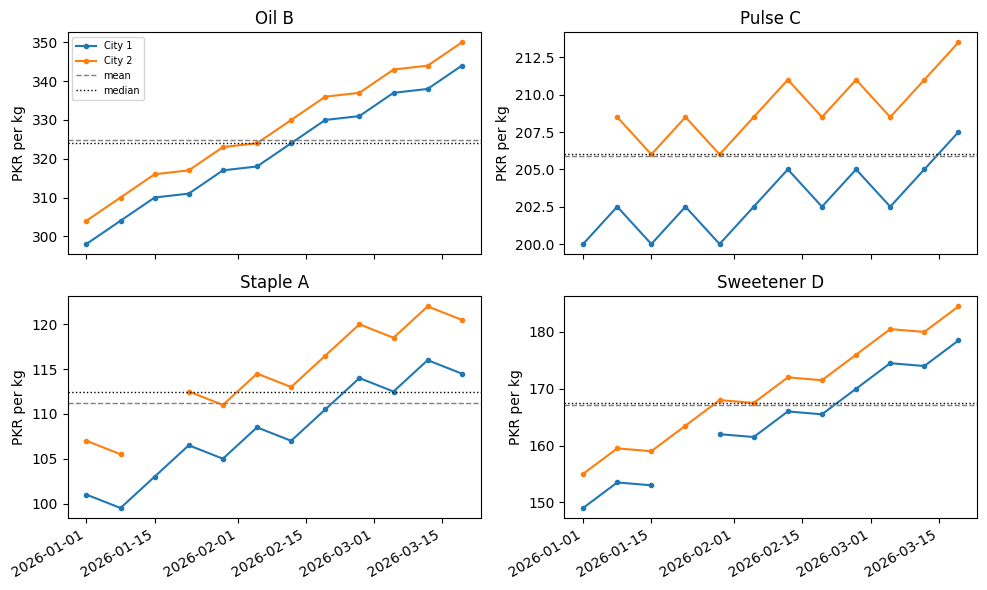

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, item in zip(axes.flat, sorted(df["item"].unique())):
    for city, sub in df[df["item"] == item].groupby("city"):
        ax.plot(sub["date"], sub["price"], marker="o", ms=3, label=city)
    ax.axhline(stats.loc[item, "mean"], ls="--", lw=1, color="grey", label="mean")
    ax.axhline(stats.loc[item, "median"], ls=":", lw=1, color="black", label="median")
    ax.set_title(item); ax.set_ylabel("PKR per kg")
axes.flat[0].legend(fontsize=7)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## Part 2 – One item with and without the flagged value (Week 2 file)
Item: **Sweetener D**, flagged value = the source price **9999** (a missing-value code).
- *With*: the source number is treated as a real price.
- *Without*: my Week 2 decision (set to missing, row kept).

In [9]:
ITEM = "Sweetener D"
s = w2[w2["item"] == ITEM]
with_flag = s["price_source"]
without_flag = s["price"]

cmp = pd.DataFrame({
    "with 9999": [with_flag.count(), with_flag.mean(), with_flag.median()],
    "without 9999": [without_flag.count(), without_flag.mean(), without_flag.median()],
}, index=["n", "mean", "median"])
cmp["change"] = cmp["with 9999"] - cmp["without 9999"]
display(cmp.round(2))

print(f"One value moves the mean by {cmp.loc['mean','change']:.2f} PKR "
      f"({cmp.loc['mean','change']/cmp.loc['mean','without 9999']*100:.0f}%); "
      f"the median moves by {cmp.loc['median','change']:.2f} PKR.")

,with 9999,without 9999,change
n,24.00,23.00,1.00
mean,576.81,167.15,409.66
median,167.75,167.50,0.25


One value moves the mean by 409.66 PKR (245%); the median moves by 0.25 PKR.


In [10]:
# Same check for Staple A and the '1,250' entry (second flagged value)
s = w2[w2["item"] == "Staple A"]
pd.DataFrame({
    "with 1250": [s["price_source"].count(), s["price_source"].mean(), s["price_source"].median()],
    "without 1250": [s["price"].count(), s["price"].mean(), s["price"].median()],
}, index=["n", "mean", "median"]).round(2)

,with 1250,without 1250
n,24.00,23.00
mean,158.71,111.26
median,112.50,112.50


## Table to paste into the AI (Step 2 – Interpretation Auditor)

In [11]:
out = stats[["n", "mean", "median", "min", "max", "first", "last", "pct_change"]].round(1)
print(out.to_markdown())

| item        |   n |   mean |   median |   min |   max |   first |   last |   pct_change |
|:------------|----:|-------:|---------:|------:|------:|--------:|-------:|-------------:|
| Oil B       |  24 |  324.8 |    324   | 298   | 350   |     301 |  347   |         15.3 |
| Pulse C     |  23 |  205.9 |    206   | 200   | 213.5 |     200 |  207.5 |          3.8 |
| Staple A    |  23 |  111.3 |    112.5 |  99.5 | 122   |     104 |  117.5 |         13   |
| Sweetener D |  23 |  167.2 |    167.5 | 149   | 184.5 |     152 |  181.5 |         19.4 |
